# Post 02 — Does a good forecast mean the model knows the lever?

**Question:** if a forecaster's predictions closely match what a system actually did,
does that mean it has learned how the system *responds* to its controls — or just what
the system's existing policy tends to do?

This is the question at the center of Amria et al. (2026),
["Time-series Foundation Models for Predictive Control: The Role of Excitation"](https://arxiv.org/abs/2610.06447)
(`literature/excitation-2026.pdf`). They study it on real building heat-pump control: a
zero-shot Chronos-2 forecast can nail a building's indoor-temperature trajectory under
its existing controller, while being essentially *insensitive* to a hypothetical change
in that controller's setpoint — unless the historical context it's conditioning on
contains genuinely independent variation in the control signal itself, which they call
**excitation**. Fine-tuning and multi-scale control features reduce how much excitation
is needed, but in their experiments never eliminate the need for it.

## Why this demo is synthetic, unlike the rest of this series

Every other demo in this repo (see the root [README](../../README.md)) runs on real CISO
electricity demand or SPY prices. This one can't: testing whether a forecast responds
*correctly* to an intervention requires knowing the ground-truth counterfactual — what
would actually have happened under a different control — and no historical series can
give us that, because history only ran once. The paper itself relies mainly on a
building simulator for the same reason, with one real-building check that explicitly
*can't* be scored against ground truth (its Fig. 5, "the house ran once").

So: a small, fully synthetic, fully known linear system, where we get to both apply any
control we like *and* know exactly what would happen. Everything here is built on
`src/control.py`.

## The toy system

A first-order system — think of it as a single room with a heater:

```
T[t+1] = a·T[t] + b·U[t] + c·D[t] + noise
```

`T` is room temperature (the forecast target), `U` is a controllable heater input, `D`
is an uncontrolled disturbance (outdoor weather, say). We generate historical context
data two different ways:

- **Unexcited** — a closed-loop proportional controller tracks a slowly time-varying
  setpoint. `U` is a *deterministic function of the state and time*: watching it tells
  you almost nothing you couldn't already infer from `T` itself.
- **Excited** — the control follows an APRBS (amplitude-modulated pseudo-random binary
  sequence): a signal that jumps between levels at randomized intervals, independent of
  the system's state.

Both regimes drive the *same* underlying system. The question is whether Chronos-2,
conditioned on one or the other as context, can tell you what happens if you change the
control — and whether a baseline that's handed the correct *functional form* (because we
built the system to be linear) but has to fit its coefficients from the context can.

In [1]:
import sys
import warnings

sys.path.insert(0, "../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.control import (
    build_offset_probes,
    chronos_control_forecast,
    fit_linear_arx,
    generate_aprbs,
    linear_arx_forecast,
    response_gain,
    rollout_from,
    simulate_closed_loop,
    simulate_disturbance,
    simulate_open_loop,
)
from src.evaluation import mae

warnings.filterwarnings("ignore")
RESULTS_DIR = "../../results/02-excitation-for-control"


## Scale

As in every notebook in this series: `SMALL_SCALE = True` keeps the sweep small (few
context lengths, few repeats per setting) so this runs in well under a minute — Chronos-2
zero-shot calls are fast once the model is loaded, so the main cost of the full-scale
version is just more repeats for tighter estimates, not a fundamentally longer run.

In [2]:
SMALL_SCALE = True

if SMALL_SCALE:
    CONTEXT_LENGTHS = [50, 150, 400]
    N_REPEATS = 4
else:
    CONTEXT_LENGTHS = [50, 100, 200, 400, 800]
    N_REPEATS = 20

# --- system dynamics: T[t+1] = A*T[t] + B*U[t] + C*D[t] + noise ---
A, B, C = 0.85, 0.4, 0.1
NOISE_STD = 0.05

# --- disturbance (weather-like) ---
DIST_PERIOD, DIST_AMPLITUDE, DIST_NOISE = 200, 1.0, 0.05

# --- "unexcited" closed-loop policy: tracks a slowly time-varying setpoint ---
KP = 0.8
U_MIN, U_MAX = -10.0, 10.0

# --- "excited" APRBS signal, two excitation amplitudes ---
MIN_DWELL, MAX_DWELL = 3, 15
EXCITATION_AMPLITUDES = {"excited-low": 1.5, "excited-high": 6.0}
REGIMES = ["unexcited", "excited-low", "excited-high"]

# --- counterfactual probes: constant offsets from the nominal future control ---
OFFSETS = [-6, -2, 0, 2, 6]
HORIZON = 24

GLOBAL_SEED = 0


def time_varying_setpoint(n, period=150, amplitude=2.0):
    return amplitude * np.sin(2 * np.pi * np.arange(n) / period)


## One example window per regime, made concrete

Before running the full sweep, look at what "unexcited" and "excited" context actually
look like for the same system.

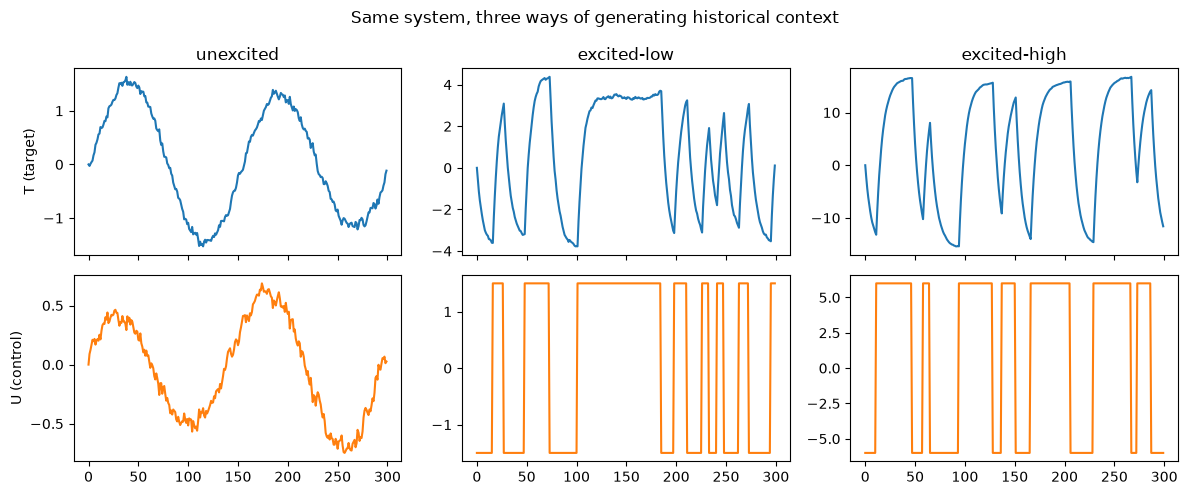

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True)
example_rng = np.random.default_rng(1)
example_length = 300

for col, regime in enumerate(REGIMES):
    disturbance = simulate_disturbance(example_length, DIST_PERIOD, DIST_AMPLITUDE, DIST_NOISE, example_rng)
    if regime == "unexcited":
        setpoint = time_varying_setpoint(example_length)
        target, control = simulate_closed_loop(
            disturbance, setpoint=setpoint, kp=KP, u_min=U_MIN, u_max=U_MAX,
            a=A, b=B, c=C, noise_std=NOISE_STD, rng=example_rng,
        )
    else:
        control = generate_aprbs(example_length, EXCITATION_AMPLITUDES[regime], MIN_DWELL, MAX_DWELL, example_rng)
        target = simulate_open_loop(control, disturbance, a=A, b=B, c=C, noise_std=NOISE_STD, rng=example_rng)

    axes[0, col].plot(target, color="tab:blue")
    axes[0, col].set_title(regime)
    axes[1, col].plot(control, color="tab:orange")

axes[0, 0].set_ylabel("T (target)")
axes[1, 0].set_ylabel("U (control)")
fig.suptitle("Same system, three ways of generating historical context")
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/example_regimes.png", dpi=150)
plt.show()


Under "unexcited," the control signal is a smooth, slow function of the state and
time — exactly as informative as the setpoint schedule already is on its own, nothing
more. Under "excited," it jumps around independently of what the room is doing. Same
system, same scale of control effort, very different *information content* about how `U`
actually moves `T`.

## The sweep

For each regime and context length, repeat several times: build a context window, fit
both models on it, forecast five matched counterfactual probes (constant offsets from
the nominal future control), and score against the *true* simulated response to each
probe.

In [4]:
def make_window(regime, context_length, rng):
    total = context_length + HORIZON
    disturbance = simulate_disturbance(total, DIST_PERIOD, DIST_AMPLITUDE, DIST_NOISE, rng)
    disturbance_context, disturbance_future = disturbance[:context_length], disturbance[context_length:]

    if regime == "unexcited":
        setpoint = time_varying_setpoint(context_length)
        target_context, control_context = simulate_closed_loop(
            disturbance_context, setpoint=setpoint, kp=KP, u_min=U_MIN, u_max=U_MAX,
            a=A, b=B, c=C, noise_std=NOISE_STD, rng=rng,
        )
    else:
        amplitude = EXCITATION_AMPLITUDES[regime]
        control_context = generate_aprbs(context_length, amplitude, MIN_DWELL, MAX_DWELL, rng)
        target_context = simulate_open_loop(control_context, disturbance_context, a=A, b=B, c=C, noise_std=NOISE_STD, rng=rng)

    # Nominal future control: hold the last applied control constant. Probes are
    # constant offsets from that -- simplified from the paper's MPC-trajectory nominal,
    # but preserves the same idea: one plausible "no change" plan, perturbed by a lever.
    nominal_future_control = np.full(HORIZON, control_context[-1])
    probes = build_offset_probes(nominal_future_control, OFFSETS, u_min=U_MIN, u_max=U_MAX)

    realized = {
        offset: rollout_from(target_context[-1], probe_control, disturbance_future,
                              a=A, b=B, c=C, noise_std=NOISE_STD, rng=rng)
        for offset, probe_control in probes.items()
    }
    return {
        "target_context": target_context,
        "control_context": control_context,
        "disturbance_context": disturbance_context,
        "disturbance_future": disturbance_future,
        "probes": probes,
        "realized": realized,
    }


def score_window(window):
    rows = []

    chronos_pred = {
        offset: chronos_control_forecast(
            window["target_context"], window["control_context"], window["disturbance_context"],
            probe_control, window["disturbance_future"],
        )
        for offset, probe_control in window["probes"].items()
    }

    arx_coeffs = fit_linear_arx(window["target_context"], window["control_context"], window["disturbance_context"])
    arx_pred = {
        offset: linear_arx_forecast(arx_coeffs, window["target_context"][-1], probe_control, window["disturbance_future"])
        for offset, probe_control in window["probes"].items()
    }

    realized_stack = np.stack([window["realized"][o] for o in OFFSETS])
    nominal_idx = OFFSETS.index(0)

    for model_name, pred in [("Chronos-2 (+covariates)", chronos_pred), ("Linear ARX (per-window fit)", arx_pred)]:
        pred_stack = np.stack([pred[o] for o in OFFSETS])
        rows.append({
            "model": model_name,
            "nominal_mae": mae(realized_stack[nominal_idx], pred_stack[nominal_idx]),
            "response_gain": response_gain(realized_stack, pred_stack),
        })
    return rows


In [5]:
rng = np.random.default_rng(GLOBAL_SEED)
rows = []

for regime in REGIMES:
    for context_length in CONTEXT_LENGTHS:
        for repeat in range(N_REPEATS):
            window = make_window(regime, context_length, rng)
            for row in score_window(window):
                rows.append({"regime": regime, "context_length": context_length, "repeat": repeat, **row})

results = pd.DataFrame(rows)
results.to_csv(f"{RESULTS_DIR}/metrics/excitation_sweep_raw.csv", index=False)
results.head()


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

,regime,context_length,repeat,model,nominal_mae,response_gain
0,unexcited,50,0,Chronos-2 (+covariates),0.096027,-0.008788
1,unexcited,50,0,Linear ARX (per-window fit),0.154339,0.653504
2,unexcited,50,1,Chronos-2 (+covariates),0.473782,-0.021887
3,unexcited,50,1,Linear ARX (per-window fit),0.086795,1.350052
4,unexcited,50,2,Chronos-2 (+covariates),0.148989,-0.043129


## Results: gain needs excitation, accuracy doesn't care

In [6]:
summary = (
    results.groupby(["model", "regime", "context_length"])
    .agg(mean_gain=("response_gain", "mean"), mean_nominal_mae=("nominal_mae", "mean"), n=("response_gain", "size"))
    .reset_index()
)
summary.to_csv(f"{RESULTS_DIR}/metrics/excitation_sweep_summary.csv", index=False)
summary


,model,regime,context_length,mean_gain,mean_nominal_mae,n
0,Chronos-2 (+covariates),excited-high,50,0.235153,8.336477,4
1,Chronos-2 (+covariates),excited-high,150,0.491816,2.954332,4
2,Chronos-2 (+covariates),excited-high,400,0.728342,1.620337,4
3,Chronos-2 (+covariates),excited-low,50,0.160496,0.996828,4
4,Chronos-2 (+covariates),excited-low,150,0.483953,0.465488,4
5,Chronos-2 (+covariates),excited-low,400,0.672564,0.229528,4
6,Chronos-2 (+covariates),unexcited,50,-0.022626,0.199667,4
7,Chronos-2 (+covariates),unexcited,150,-0.003474,0.368324,4
8,Chronos-2 (+covariates),unexcited,400,-0.012876,0.217460,4
9,Linear ARX (per-window fit),excited-high,50,0.998804,0.112852,4


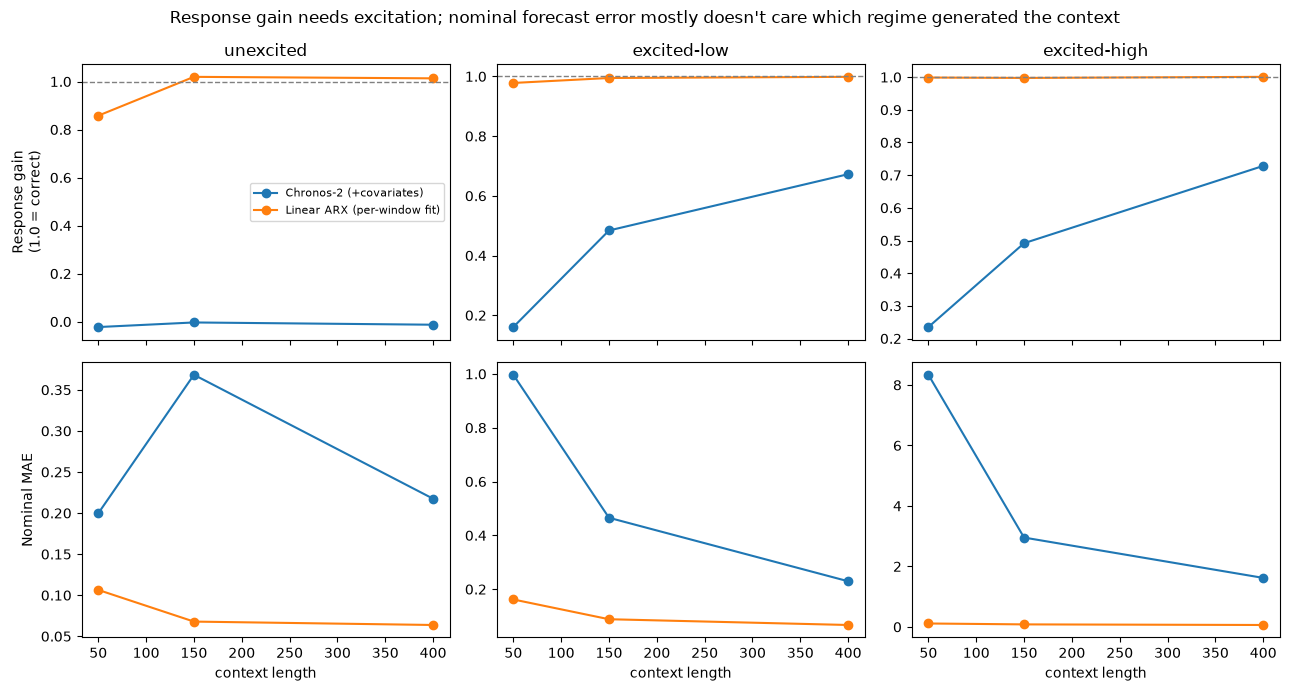

In [7]:
fig, axes = plt.subplots(2, len(REGIMES), figsize=(13, 7), sharex=True)
models = summary["model"].unique()

for col, regime in enumerate(REGIMES):
    regime_summary = summary[summary["regime"] == regime]
    for model in models:
        model_summary = regime_summary[regime_summary["model"] == model].sort_values("context_length")
        axes[0, col].plot(model_summary["context_length"], model_summary["mean_gain"], marker="o", label=model)
        axes[1, col].plot(model_summary["context_length"], model_summary["mean_nominal_mae"], marker="o", label=model)
    axes[0, col].axhline(1.0, color="gray", linestyle="--", linewidth=1)
    axes[0, col].set_title(regime)
    axes[1, col].set_xlabel("context length")

axes[0, 0].set_ylabel("Response gain\n(1.0 = correct)")
axes[1, 0].set_ylabel("Nominal MAE")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Response gain needs excitation; nominal forecast error mostly doesn't care which regime generated the context")
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/gain_and_mae_by_regime.png", dpi=150)
plt.show()


## One example, made concrete

Pick a single window at the longest context length, under the unexcited and the
most-excited regime, and look at what Chronos-2 actually predicts for each probe against
what really happens.

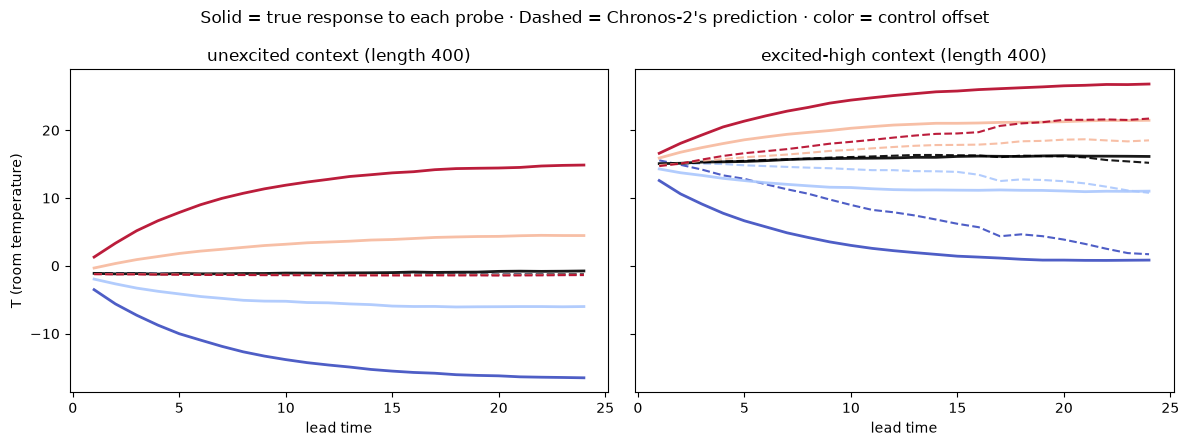

In [8]:
example_context_length = CONTEXT_LENGTHS[-1]
example_rng = np.random.default_rng(99)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
lead_times = np.arange(1, HORIZON + 1)

for ax, regime in zip(axes, ["unexcited", "excited-high"]):
    window = make_window(regime, example_context_length, example_rng)
    for offset, probe_control in window["probes"].items():
        predicted = chronos_control_forecast(
            window["target_context"], window["control_context"], window["disturbance_context"],
            probe_control, window["disturbance_future"],
        )
        realized = window["realized"][offset]
        color = "black" if offset == 0 else plt.cm.coolwarm((offset + 6) / 12)
        ax.plot(lead_times, realized, color=color, linewidth=2, alpha=0.9)
        ax.plot(lead_times, predicted, color=color, linestyle="--", alpha=0.9)
    ax.set_title(f"{regime} context (length {example_context_length})")
    ax.set_xlabel("lead time")

axes[0].set_ylabel("T (room temperature)")
fig.suptitle("Solid = true response to each probe · Dashed = Chronos-2's prediction · color = control offset")
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/figures/example_probes.png", dpi=150)
plt.show()


## Reading the results

- The top row of the sweep plot is the paper's central claim, reproduced at toy scale:
  response gain stays near 0 under an unexcited context regardless of how much of it
  there is, and climbs toward 1 only once the context contains genuine, independent
  excitation — and more so at higher excitation amplitude.
- The bottom row is the point that makes this worth writing about: nominal forecast
  accuracy on the trajectory that actually happened barely distinguishes these regimes.
  A model can be *equally good* at predicting what already happened while being *totally
  different* at predicting what would happen under a change — exactly the gap standard
  forecast evaluation (the kind used everywhere else in this repo) cannot see.
- The linear ARX baseline has a real, disclosed advantage here: it's handed the *correct*
  functional form, because we built the toy system to be linear. Its gain story is still
  worth reading — where it beats Chronos-2, and where it doesn't once Chronos-2 has
  enough excited context, says something about how much of this gap is "wrong inductive
  bias" versus "insufficient identification signal," which a correctly-biased model
  doesn't need as much of.
- The example-probe plot shows the mechanism directly: under an unexcited context, the
  dashed lines (predictions) barely fan out across offsets while the solid lines (truth)
  fan out a lot — the model is predicting almost the *same* trajectory regardless of what
  you tell it the future control will be. Under excitation, the dashed lines start to
  track the solid ones.
- None of this says anything about *real* buildings, markets, or grids — it's a linear
  toy system built so we could know the ground truth. Treat it as showing the mechanism
  is real and reproducible at small scale, not as evidence about its size or importance
  in any real deployment; that's exactly the caveat the source paper places on its own,
  considerably more realistic, simulation.
- Set `SMALL_SCALE = False` and rerun for tighter estimates (more repeats per setting).